# Titanic - Machine Learning from Disaster
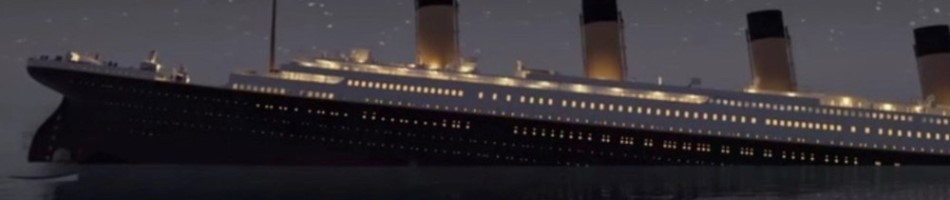
[Overview - Kaggle.com](https://www.kaggle.com/competitions/titanic/overview)

Построим модель, которая предсказывает, выжил ли пассажир Титаника.

Начнём с логистической регрессии и случайного леса, добавим `Title`
и подберём параметры леса.

Затем обучим CatBoost на тех же признаках,
разберём раннюю остановку и настроим бустинг с помощью Optuna.

Сравним модели на одинаковых фолдах.

Лучшую по средней CV accuracy обучим на всех размеченных данных и подготовим `submission.csv`.

## Установка библиотек

In [ ]:
%pip install optuna
%pip install catboost

## Подключение библиотек

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import optuna
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

RANDOM_STATE = 42
N_TRIALS = 20
TUNE_RF = True
TUNE_CATBOOST = True
COLORS = ("#2563EB", "#F97316")

plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## Описание данных

| Столбец | Описание |
| --- | --- |
| `Survived` | Целевая переменная: 1 — пассажир выжил, 0 — погиб. |
| `PassengerId` | Идентификатор пассажира. |
| `Pclass` | Класс билета: 1, 2 или 3. |
| `Name` | Имя пассажира, включая обращение или титул. |
| `Sex` | Пол пассажира. |
| `Age` | Возраст в годах. |
| `SibSp` | Число братьев, сестёр и супругов на борту. |
| `Parch` | Число родителей и детей на борту. |
| `Ticket` | Номер билета. |
| `Fare` | Стоимость билета. |
| `Cabin` | Номер каюты. |
| `Embarked` | Порт посадки: C, Q или S. |

## Загрузка данных

В `train_data` есть ответы `Survived`. На этих данных будем обучать
и сравнивать модели.

В `test_data` ответов нет — для этих пассажиров
подготовим прогнозы для соревнования.

In [ ]:
url_train = "https://drive.google.com/file/d/1nHQC99k2GlUl06yshOX76DUKTelVVJbe/view?usp=drive_link"
url_train = "https://drive.google.com/uc?id=" + url_train.split("/")[-2]
train_data = pd.read_csv(url_train)

url_test = "https://drive.google.com/file/d/1x__b9TA3x_sqJrZb_bcvqQfAUa3ZqCXx/view?usp=drive_link"
url_test = "https://drive.google.com/uc?id=" + url_test.split("/")[-2]
test_data = pd.read_csv(url_test)

In [ ]:
train_data = train_data.sort_values("PassengerId").reset_index(drop=True)
test_data = test_data.sort_values("PassengerId").reset_index(drop=True)

print(f"Размеченных пассажиров: {len(train_data)}")
print(f"Пассажиров в конкурсном test: {len(test_data)}")
display(train_data.head())
display(test_data.head())

In [ ]:
train_data.info()
display(train_data.describe().round(2))

## Анализ данных

Посмотрим на соотношение классов и пропуски.

Пропуски исследуем в обоих файлах: обработка, обученная на размеченных данных, должна подходить и к test.

In [ ]:
class_shares = train_data["Survived"].value_counts(normalize=True).sort_index()

missing_counts = (
    pd.DataFrame({"Train": train_data.isna().sum(), "Test": test_data.isna().sum()})
    .fillna(0)
    .astype(int)
)

missing_counts = missing_counts.loc[missing_counts.any(axis=1)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar(["Погиб", "Выжил"], class_shares, color=COLORS)
axes[0].bar_label(
    bars,
    labels=[f"{share:.1%}" for share in class_shares],
    padding=3,
)
axes[0].set(
    title="Распределение целевой переменной",
    ylabel="Доля пассажиров",
    ylim=(0, class_shares.max() * 1.15),
)
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=1))

missing_counts.plot.barh(ax=axes[1], color=COLORS)
for container in axes[1].containers:
    labels = [str(int(value)) if value else "" for value in container.datavalues]
    axes[1].bar_label(container, labels=labels, padding=3)

axes[1].set_xlim(0, missing_counts.to_numpy().max() * 1.15)
axes[1].set(
    title="Пропуски в данных",
    xlabel="Число пропусков",
    ylabel="Признак",
)

fig.tight_layout()
plt.show()

Как связана доля выживших с полом и классом билета?

Рядом с долями посмотрим число пассажиров в каждой группе.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, feature, title in zip(
    axes,
    ["Sex", "Pclass"],
    ["Выживаемость и пол", "Выживаемость и класс билета"],
    strict=True,
):
    summary = train_data.groupby(feature)["Survived"].agg(["mean", "size"])
    display(
        summary.rename(columns={"mean": "Доля выживших", "size": "Пассажиров"}).round(3)
    )
    bars = ax.bar(summary.index.astype(str), summary["mean"], color=COLORS[0])
    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set(title=title, xlabel=feature, ylabel="Доля выживших", ylim=(0, 1))
fig.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for class_id, label in [(0, "Погиб"), (1, "Выжил")]:
    passengers = train_data.loc[train_data["Survived"] == class_id]
    sns.kdeplot(
        data=passengers,
        x="Age",
        ax=axes[0],
        fill=True,
        alpha=0.3,
        cut=0,
        clip=(0, None),
        color=COLORS[class_id],
        label=label,
    )
    sns.kdeplot(
        data=passengers,
        x="Fare",
        ax=axes[1],
        fill=True,
        alpha=0.3,
        cut=0,
        clip=(0, None),
        color=COLORS[class_id],
        label=label,
    )

axes[0].set(
    title="Распределение возраста (KDE)", xlabel="Возраст, лет", ylabel="Плотность"
)
axes[1].set(
    title="Распределение стоимости билета (KDE)",
    xlabel="Стоимость билета",
    ylabel="Плотность",
)
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## Признаки и разделение данных

Начнём с признаков `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`.

`PassengerId` оставим для файла с прогнозами.

`Name`, `Ticket` и `Cabin` пока не используем.

Выделим train и validation один раз. Это позволит сравнивать модели
на одних и тех же пассажирах. Все обучаемые преобразования выполняем
после разделения.

In [ ]:
base_features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

x = train_data[base_features].copy()
y = train_data["Survived"]

x_train, x_valid, y_train, y_valid = train_test_split(
    x,
    y,
    train_size=0.8,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Train: {len(y_train)} пассажиров")
print(f"Validation: {len(y_valid)} пассажиров")

## Заполнение пропусков и кодирование

Числовые пропуски заполним медианой, пропуски в категориальных признаках —
модой.

Для `Sex` используем `OrdinalEncoder`, для `Embarked` — one-hot encoding.

In [ ]:
def make_preprocessor(include_title: bool = False) -> ColumnTransformer:
    """Подготовить числовые и категориальные признаки."""
    transformers = [
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features,
        ),
        (
            "sex",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
            ),
            ["Sex"],
        ),
        (
            "embarked",
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
            ["Embarked"],
        ),
    ]
    if include_title:
        transformers.append(
            (
                "title",
                OneHotEncoder(
                    drop="first", handle_unknown="ignore", sparse_output=False
                ),
                ["Title"],
            )
        )
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

## Логистическая регрессия

Начнём с логистической регрессии. После заполнения пропусков
и кодирования стандартизируем признаки.

Качество оценим на train и validation с помощью accuracy.

In [ ]:
model_lr = Pipeline(
    [
        ("preprocessor", make_preprocessor()),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ]
)
model_lr.fit(x_train, y_train)

In [ ]:
lr_scores = {
    "Модель": "Логистическая регрессия",
    "Train accuracy": accuracy_score(y_train, model_lr.predict(x_train)),
    "Validation accuracy": accuracy_score(y_valid, model_lr.predict(x_valid)),
}
display(pd.DataFrame([lr_scores]).set_index("Модель").round(4))

## Случайный лес

Используем те же исходные признаки и то же разбиение.
Для всех вариантов случайного леса масштабирование не используем:
деревьям оно обычно не требуется.

In [ ]:
model_rf = Pipeline(
    [
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    ]
)
model_rf.fit(x_train, y_train)

rf_scores = {
    "Модель": "Случайный лес",
    "Train accuracy": accuracy_score(y_train, model_rf.predict(x_train)),
    "Validation accuracy": accuracy_score(y_valid, model_rf.predict(x_valid)),
}
display(pd.DataFrame([rf_scores]).set_index("Модель").round(4))

## Дополнительный признак из имени

Извлечём обращение или титул из `Name`: например, `Mr`, `Mrs`, `Master`,
`Dr`.

Он может содержать информацию, полезную для предсказания: профессию или статус.

Сохраним исходную группировку: обычные обращения объединим в `NoTitle`,
остальные — в группы `Master`, `Military`, `Doctor`, `Reverend`, `Noble`.

In [ ]:
title_mapping = {
    "Mr": "NoTitle",
    "Miss": "NoTitle",
    "Mlle": "NoTitle",
    "Ms": "NoTitle",
    "Mrs": "NoTitle",
    "Mme": "NoTitle",
    "Master": "Master",
    "Capt": "Military",
    "Col": "Military",
    "Major": "Military",
    "Dr": "Doctor",
    "Rev": "Reverend",
    "Lady": "Noble",
    "Countess": "Noble",
    "Sir": "Noble",
    "Don": "Noble",
    "Dona": "Noble",
    "Jonkheer": "Noble",
}


def add_title(data: pd.DataFrame) -> pd.DataFrame:
    """Извлечь обращение из имени и применить фиксированную группировку"""
    result = data.copy()
    titles = result["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
    result["Title"] = titles.replace(title_mapping).fillna("Unknown")
    return result


train_with_title = add_title(train_data)
display(train_with_title[["Name", "Title"]].head(10))

In [ ]:
title_counts = train_with_title["Title"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(title_counts.index, title_counts, color=COLORS[0])
ax.bar_label(bars, padding=3)
ax.set(title="Обращения и титулы после группировки", xlabel="Число пассажиров")
ax.set_xlim(0, title_counts.max() * 1.15)
fig.tight_layout()
plt.show()

In [ ]:
extended_features = base_features + ["Title"]
x_add = train_with_title[extended_features].copy()
x_train_add = x_add.loc[x_train.index]
x_valid_add = x_add.loc[x_valid.index]

model_rf_title = Pipeline(
    [
        ("preprocessor", make_preprocessor(include_title=True)),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    ]
)
model_rf_title.fit(x_train_add, y_train)

rf_title_scores = {
    "Модель": "Лес с Title",
    "Train accuracy": accuracy_score(y_train, model_rf_title.predict(x_train_add)),
    "Validation accuracy": accuracy_score(y_valid, model_rf_title.predict(x_valid_add)),
}
display(pd.DataFrame([rf_title_scores]).set_index("Модель").round(4))

## Подбор гиперпараметров с помощью Optuna для RF

Для окончательного подбора используем весь обучающий датасет (891 размеченный объект) и StratifiedCV.

Для подбора гиперпараметров используем 'optuna' - максимизируем среднюю accuracy по CV.

В `Pipeline` включена обработка признаков, поэтому медианы и кодирование
обучаются только на train внутри CV.

Лучший CV-score — оценка, по которой выбирались параметры, и она может быть оптимистичной.

Для воспроизводимости фиксируем seed у разбиения, леса и Optuna;
испытания и обучение запускаем последовательно.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def objective_rf(trial: optuna.Trial) -> float:
    """Оценить настройки случайного леса на пяти фолдах."""
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 500),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 100),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.1, 1.0),
        "ccp_alpha": trial.suggest_float("ccp_alpha", 1e-8, 1.0, log=True),
    }
    model = Pipeline(
        [
            ("preprocessor", make_preprocessor(include_title=True)),
            (
                "model",
                RandomForestClassifier(**params, random_state=RANDOM_STATE, n_jobs=1),
            ),
        ]
    )
    scores = cross_val_score(
        model, x_add, y, cv=cv, scoring="accuracy", n_jobs=1, error_score="raise"
    )
    return float(scores.mean())


optuna.logging.set_verbosity(optuna.logging.WARNING)
study_rf = None
if TUNE_RF:
    sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
    study_rf = optuna.create_study(sampler=sampler, direction="maximize")
    study_rf.optimize(objective_rf, n_trials=N_TRIALS, n_jobs=1, show_progress_bar=True)
else:
    print("Подбор параметров леса отключён: сравним модели без настроенного RF.")

In [ ]:
if study_rf is not None:
    print(f"Лучшая средняя CV accuracy: {study_rf.best_value:.4f}")
    display(pd.Series(study_rf.best_params, name="Значение", dtype=object).to_frame())

In [ ]:
if study_rf is not None:
    fig = optuna.visualization.plot_optimization_history(study_rf)
    fig.update_layout(
        title="Подбор гиперпараметров случайного леса",
        xaxis_title="Номер испытания",
        yaxis_title="Средняя CV accuracy",
        template="plotly_white",
    )
    fig.show()

## CatBoost

Используем те же восемь признаков, что у RF с `Title`, и такой же сплит.


`Sex`, `Embarked` и `Title` передадим как категории - catboost кодирует их "из коробки". Внешние кодировщики, скейлер и заполнение числовых пропусков не нужны.
Категориальные пропуски обозначим строкой `Unknown`.

`Pclass`, как и раньше, оставим числовым порядковым признаком.



CatBoost сам вычисляет статистики категорий и их комбинаций,
а для малочисленных категорий может использовать встроенный one-hot.

`Pool` хранит данные, ответы и описание категориальных признаков - используется как удобный способ описать трейн и валид выборки.

In [ ]:
categorical_features = ["Sex", "Embarked", "Title"]
x_cat = x_add.copy()
x_cat[categorical_features] = x_cat[categorical_features].fillna("Unknown").astype(str)
x_train_cat = x_cat.loc[x_train.index]
x_valid_cat = x_cat.loc[x_valid.index]

train_pool = Pool(x_train_cat, y_train, cat_features=categorical_features)
valid_pool = Pool(x_valid_cat, y_valid, cat_features=categorical_features)

display(x_train_cat.head())
display(x_cat.isna().sum().rename("Пропусков").to_frame())

## Обучение CatBoost и ранняя остановка

Обучаем модель с функцией потерь `Logloss`. Качество решения оцениваем
по accuracy — метрике соревнования.

Параметр `boosting_type` задаёт схему бустинга. Используем `Plain` —
классическую схему градиентного бустинга.

Альтернативная схема `Ordered` использует случайные перестановки объектов: при вычислении градиента для объекта используются предсказания вспомогательной модели, обученной только на предшествующих объектах перестановки.
Таким образом, собственный ответ объекта не используется при обучении
модели, по которой вычисляется его градиент.

Параметр `early_stopping_rounds=50` включает детектор переобучения
типа `Iter`: обучение останавливается, когда после итерации с лучшим
значением метрики прошло 50 итераций без улучшения.
В нашем случае используется Logloss на валидационной выборке.

Параметр `use_best_model=True` определяет число деревьев,
сохраняемых в итоговой модели: по валидационной выборке выбирается
итерация с лучшим значением `eval_metric`. Деревья после этой
итерации не сохраняются.

In [ ]:
catboost_params = {
    "loss_function": "Logloss",
    "eval_metric": "Logloss",
    "cat_features": tuple(categorical_features),
    "boosting_type": "Plain",
    "random_seed": RANDOM_STATE,
    "thread_count": 1,
    "task_type": "CPU",
    "verbose": False,
    "allow_writing_files": False,
}

model_catboost = CatBoostClassifier(
    **catboost_params,
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,

)
model_catboost.fit(
    train_pool,
    eval_set=valid_pool,
    early_stopping_rounds=150,
    use_best_model=True,
)

print(f"Лучшая итерация: {model_catboost.get_best_iteration() + 1}")
print(f"Сохранено деревьев: {model_catboost.tree_count_}")
catboost_scores = {
    "Модель": "CatBoost + Title",
    "Train accuracy": accuracy_score(y_train, model_catboost.predict(train_pool)),
    "Validation accuracy": accuracy_score(y_valid, model_catboost.predict(valid_pool)),
}
display(pd.DataFrame([catboost_scores]).set_index("Модель").round(4))

In [ ]:
learning_history = model_catboost.get_evals_result()
train_loss = learning_history["learn"]["Logloss"]
valid_loss = learning_history["validation"]["Logloss"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(train_loss) + 1), train_loss, label="Train", color=COLORS[0])
ax.plot(range(1, len(valid_loss) + 1), valid_loss, label="Validation", color=COLORS[1])
ax.axvline(
    model_catboost.get_best_iteration() + 1,
    color="gray",
    linestyle="--",
    label="Лучшая итерация",
)
ax.set(
    title="CatBoost: функция потерь по итерациям",
    xlabel="Итерация",
    ylabel="Logloss",
)
ax.legend()
fig.tight_layout()
plt.show()

## Встроенный анализ CatBoost

Для модели, обученной на train, посмотрим `LossFunctionChange` на validation.
Это приближённое изменение функции потерь при исключении признака
без полного переобучения. Большее значение соответствует большей пользе
признака; отрицательное возможно. Результат зависит от выбранных данных.

Затем посмотрим сильнейшие взаимодействия признаков в предсказаниях модели через `Interaction`.

In [ ]:
loss_importances = pd.Series(
    model_catboost.get_feature_importance(data=valid_pool, type="LossFunctionChange"),
    index=x_cat.columns,
).sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(
    loss_importances.index,
    loss_importances,
    color=[COLORS[1] if value < 0 else COLORS[0] for value in loss_importances],
)
ax.axvline(0, color="gray", linewidth=1)
ax.set(
    title="CatBoost: важности по LossFunctionChange на validation",
    xlabel="Приближённое изменение Logloss без признака",
)
fig.tight_layout()
plt.show()

In [ ]:
interaction_values = model_catboost.get_feature_importance(type="Interaction")
interactions = pd.DataFrame(
    interaction_values, columns=["first_feature", "second_feature", "strength"]
)
if interactions.empty:
    print("Модель не выделила парных взаимодействий.")
else:
    interactions["Пара признаков"] = [
        f"{x_cat.columns[int(first)]} + {x_cat.columns[int(second)]}"
        for first, second in interactions[
            ["first_feature", "second_feature"]
        ].itertuples(index=False, name=None)
    ]
    top_interactions = interactions.nlargest(5, "strength").sort_values("strength")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.barh(
        top_interactions["Пара признаков"],
        top_interactions["strength"],
        color=COLORS[0],
    )
    ax.set(
        title="CatBoost: сильнейшие взаимодействия признаков",
        xlabel="Сила взаимодействия",
    )
    fig.tight_layout()
    plt.show()

## Подбор гиперпараметров с помощью Optuna для CatBoost


In [ ]:
def objective_catboost(trial: optuna.Trial) -> float:
    """Оценить настройки CatBoost на пяти фолдах."""
    params = {
        "iterations": trial.suggest_int("iterations", 200, 2000, step=100),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.15, log=True
        ),
        "depth": trial.suggest_int("depth", 3, 8),
        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 1.0, 100.0, log=True
        ),
        "random_strength": trial.suggest_float("random_strength", 0.0, 5.0),
        "max_ctr_complexity": trial.suggest_int("max_ctr_complexity", 1, 2),
        "rsm": trial.suggest_float("rsm", 0.6, 1.0),
        "border_count": trial.suggest_categorical(
            "border_count", [32, 64, 128, 254]
        ),
        "bootstrap_type": trial.suggest_categorical(
            "bootstrap_type", ["Bayesian", "Bernoulli", "MVS"]
        ),
    }

    if params["bootstrap_type"] == "Bayesian":
        params["bagging_temperature"] = trial.suggest_float(
            "bagging_temperature", 0.0, 5.0
        )
    else:
        params["subsample"] = trial.suggest_float("subsample", 0.5, 1.0)

    model = CatBoostClassifier(**catboost_params, **params)
    scores = cross_val_score(
        model,
        x_cat,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=1,
        error_score="raise",
    )
    return float(scores.mean())


study_catboost = None
if TUNE_CATBOOST:
    sampler_catboost = optuna.samplers.TPESampler(seed=RANDOM_STATE)
    study_catboost = optuna.create_study(sampler=sampler_catboost, direction="maximize")
    study_catboost.optimize(
        objective_catboost,
        n_trials=N_TRIALS,
        n_jobs=1,
        show_progress_bar=True,
    )
else:
    print("Подбор параметров CatBoost отключён: сравним базовый CatBoost.")

In [ ]:
if study_catboost is not None:
    print(f"Лучшая средняя CV accuracy CatBoost: {study_catboost.best_value:.4f}")
    display(
        pd.Series(study_catboost.best_params, name="Значение", dtype=object).to_frame()
    )

In [ ]:
if study_catboost is not None:
    fig = optuna.visualization.plot_optimization_history(study_catboost)
    fig.update_layout(
        title="Подбор гиперпараметров CatBoost",
        xaxis_title="Номер испытания",
        yaxis_title="Средняя CV accuracy",
        template="plotly_white",
    )
    fig.show()

## Сравнение результатов

Сравним обученные модели:
- логистическую регрессию
- RF
- RF + `Title`
- RF + `Title` + Optuna
- CatBoost + `Title`
- CatBoost + `Title` + Optuna

Для каждой модели вычислим CV score — среднюю accuracy по одинаковым пяти
фолдам всех размеченных данных.

Сравнение показывает эффект выбранной модели, добавления признака `Title` и настройки гиперпараметров.

In [ ]:
cv_models = {
    "LR baseline": (model_lr, x),
    "RF baseline": (model_rf, x),
    "RF + Title": (model_rf_title, x_add),
}
if study_rf is not None:
    optimized_rf = Pipeline(
        [
            ("preprocessor", make_preprocessor(include_title=True)),
            (
                "model",
                RandomForestClassifier(
                    **study_rf.best_params,
                    random_state=RANDOM_STATE,
                    n_jobs=1,
                ),
            ),
        ]
    )
    cv_models["RF + Title + Optuna"] = (optimized_rf, x_add)

cv_models["CatBoost + Title"] = (model_catboost, x_cat)
if study_catboost is not None:
    optimized_catboost = CatBoostClassifier(
        **catboost_params, **study_catboost.best_params
    )
    cv_models["CatBoost + Title + Optuna"] = (optimized_catboost, x_cat)

cv_results = []
for name, (model, features) in cv_models.items():
    fold_scores = cross_val_score(
        model,
        features,
        y,
        cv=cv,
        scoring="accuracy",
        n_jobs=1,
        error_score="raise",
    )
    cv_results.append(
        {
            "Модель": name,
            "Средняя accuracy": float(fold_scores.mean()),
            "Стандартное отклонение": float(fold_scores.std()),
        }
    )

cv_results_df = pd.DataFrame(cv_results).set_index("Модель")
display(cv_results_df.round(4))

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(
    cv_results_df.index,
    cv_results_df["Средняя accuracy"],
    xerr=cv_results_df["Стандартное отклонение"],
    capsize=4,
    color=[
        COLORS[1] if "Optuna" in name else COLORS[0] for name in cv_results_df.index
    ],
)
ax.bar_label(bars, fmt="%.3f", padding=30)
ax.invert_yaxis()
ax.set(
    title="Сравнение моделей на одинаковых пяти фолдах",
    xlabel="Средняя CV accuracy",
    xlim=(0, 1),
)
fig.tight_layout()
plt.show()

## Финальная модель и подготовка решения

Выберем модель с максимальной средней CV accuracy и заново обучим её
на всех размеченных данных.

In [ ]:
best_name = cv_results_df["Средняя accuracy"].idxmax()
best_model, best_features = cv_models[best_name]
final_model = clone(best_model)
final_model.fit(best_features, y)

print(f"Выбрана модель: {best_name}")
print(f"Средняя CV accuracy: {cv_results_df.loc[best_name, 'Средняя accuracy']:.4f}")

test_with_title = add_title(test_data)
x_test = test_with_title[best_features.columns].copy()
if isinstance(final_model, CatBoostClassifier):
    x_test[categorical_features] = (
        x_test[categorical_features].fillna("Unknown").astype(str)
    )
test_predictions = final_model.predict(x_test).reshape(-1)

## Важности признаков

Покажем оценку важности признаков для выбранной финальной модели, обученной на всех размеченных данных.

Оценка важности признаков отличается для моделей:

- RF: уменьшение неоднородности классов, приведённое к процентам.
- CatBoost: `PredictionValuesChange`, сумма важностей равна 100.
- Логистическая регрессия: коэффициенты стандартизированных признаков
  после кодирования. Знак показывает направление изменения логита
  класса «Выжил» при фиксированных остальных признаках.

Это разные меры: их значения нельзя напрямую сравнивать между моделями.
Важности не доказывают причинное влияние на выживание.

In [ ]:
if isinstance(final_model, CatBoostClassifier):
    feature_names = final_model.feature_names_
    # В этой задаче CatBoost использует PredictionValuesChange, не Джини.
    # Важности отражают изменения предсказаний и в сумме дают 100.
    feature_scores = pd.Series(
        final_model.feature_importances_, index=feature_names
    ).sort_values()
    plot_title = "CatBoost: важности по PredictionValuesChange"
    axis_label = "Важность, %"
    bar_colors = COLORS[0]
else:
    feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
    estimator = final_model.named_steps["model"]
    if isinstance(estimator, RandomForestClassifier):
        # В RF важности основаны на уменьшении неоднородности классов.
        feature_scores = pd.Series(
            estimator.feature_importances_ * 100, index=feature_names
        ).sort_values()
        plot_title = "Random Forest: уменьшение неоднородности"
        axis_label = "Важность, %"
        bar_colors = COLORS[0]
    else:
        feature_scores = pd.Series(estimator.coef_[0], index=feature_names)
        feature_scores = feature_scores.reindex(
            feature_scores.abs().sort_values().index
        )
        plot_title = "Логистическая регрессия: коэффициенты"
        axis_label = "Коэффициент после стандартизации"
        bar_colors = [COLORS[1] if value < 0 else COLORS[0] for value in feature_scores]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(feature_scores.index, feature_scores, color=bar_colors)
ax.axvline(0, color="gray", linewidth=1)
ax.set(title=plot_title, xlabel=axis_label)
fig.tight_layout()
plt.show()

In [ ]:
submission = pd.DataFrame(
    {
        "PassengerId": test_data["PassengerId"].to_numpy(),
        "Survived": test_predictions.astype(int),
    }
)

assert len(submission) == len(test_data)
assert submission["PassengerId"].is_unique
assert not submission.isna().any().any()
assert submission["Survived"].isin([0, 1]).all()

submission_path = Path("submission.csv")
submission.to_csv(submission_path, index=False, lineterminator="\n")
display(submission.head(3))
print(f"Сохранён файл: {submission_path.resolve()}")